# Indian OTT Content Intelligence Observatory: analysis walkthrough
Launch attention = English-Wikipedia pageviews in the 28 days from release. A proxy for public interest, not viewership. All logic lives in `src/ott_intel`; this notebook calls it.

In [1]:
import sys, warnings; sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
from ott_intel import analysis as A, db
pd.options.display.float_format = '{:,.3f}'.format
t = A.load(); s = A.sample(t)
len(t), int((t.scripted==1).sum()), len(s)

(998, 920, 502)

## 1. Coverage: who can be measured?

In [2]:
c = A.coverage(t); c[c.dimension.isin(['platform','primary_language'])]

,level,titles,measurable,share_measurable,dimension
0,ALTT,22,11,0.500,platform
1,Aha,62,11,0.177,platform
2,Amazon Prime Video,157,106,0.675,platform
3,ETV Win,15,3,0.200,platform
4,Hoichoi,40,4,0.100,platform
5,JioHotstar,180,101,0.561,platform
6,MX Player,30,4,0.133,platform
7,Netflix,129,108,0.837,platform
8,SonyLIV,77,37,0.481,platform
9,TVF Play,2,0,0.000,platform


## 2. SQL examples (window functions and CTEs)

In [3]:
import sqlite3; con = sqlite3.connect(db.DB)
db.run_query('q02_release_trend', con).head(12)

,platform,release_year,n,change_vs_prior_year,cumulative_titles
0,ALTT,2018,13,NaN,13
1,ALTT,2019,6,-7.000,19
2,ALTT,2020,1,-5.000,20
3,ALTT,2021,2,1.000,22
4,Aha,2020,11,NaN,11
5,Aha,2021,11,0.000,22
6,Aha,2022,15,4.000,37
7,Aha,2023,5,-10.000,42
8,Aha,2024,11,6.000,53
9,Aha,2025,9,-2.000,62


In [4]:
db.run_query('q05_top_titles_per_platform', con).head(12)

,platform,rk,wiki_title,primary_language,primary_genre,release_year,launch_views
0,ALTT,1,Dil Hi Toh Hai,Hindi,Drama,2018,118130
1,ALTT,2,Gandii Baat,Hindi,Comedy,2018,98891
2,ALTT,3,Puncch Beat,Hindi,Romance,2019,42161
3,Aha,1,Colour Photo,Telugu,Historical,2020,146303
4,Aha,2,Super Over (film),Telugu,Crime,2021,44339
5,Aha,3,Maruthi Nagar Police Station,Tamil,Crime,2023,42776
6,Amazon Prime Video,1,Jai Bhim (film),Tamil,Drama,2021,2030573
7,Amazon Prime Video,2,Shershaah,Hindi,Biographical,2021,1660530
8,Amazon Prime Video,3,Soorarai Pottru,Tamil,Drama,2020,1484262
9,ETV Win,1,Anaganaga (film),Telugu,Drama,2025,236717


## 3. Distribution of launch attention

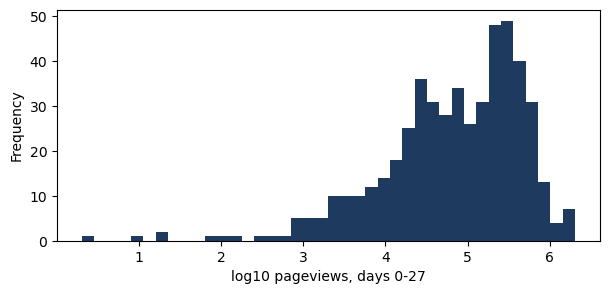

In [5]:
ax = s.log_views.plot.hist(bins=40, figsize=(7,3), color='#1F3A5F'); ax.set_xlabel('log10 pageviews, days 0-27');

In [6]:
pd.concat([A.group_stats(s, c) for c in ('primary_language','primary_genre','format')])[['dimension','level','titles','median_views','p25','p75','kruskal_p']]

,dimension,level,titles,median_views,p25,p75,kruskal_p
0,primary_language,Bengali,15,"5,646.000","2,418.000","12,574.500",0.000
2,primary_language,Hindi,292,"143,885.000","35,333.000","363,326.750",0.000
4,primary_language,Malayalam,36,"97,356.500","24,413.250","233,896.250",0.000
5,primary_language,Marathi,11,"10,040.000","3,470.000","25,533.500",0.000
7,primary_language,Tamil,83,"86,423.000","28,066.500","321,704.000",0.000
8,primary_language,Telugu,53,"30,237.000","14,697.000","110,238.000",0.000
0,primary_genre,Action,43,"197,050.000","50,107.500","560,189.500",0.001
1,primary_genre,Biographical,11,"286,479.000","177,916.000","672,184.000",0.001
2,primary_genre,Comedy,81,"86,505.000","28,160.000","227,140.000",0.001
3,primary_genre,Crime,86,"146,302.500","29,282.250","360,269.750",0.001


## 4. Associations with controls (OLS on log10 views, HC3)

In [7]:
coef, m = A.ols(s)
coef[~coef.term.str.contains('release_year')][['term','multiplier','mult_low','mult_high','p_value']]

,term,multiplier,mult_low,mult_high,p_value
0,Intercept,"37,037.338","7,455.543","183,992.550",0.000
1,"C(platform, Treatment('Netflix'))[T.Amazon Pri...",0.866,0.557,1.347,0.524
2,"C(platform, Treatment('Netflix'))[T.JioHotstar]",0.442,0.272,0.719,0.001
3,"C(platform, Treatment('Netflix'))[T.Other]",0.197,0.077,0.505,0.001
4,"C(platform, Treatment('Netflix'))[T.SonyLIV]",0.319,0.155,0.658,0.002
5,"C(platform, Treatment('Netflix'))[T.ZEE5]",0.225,0.137,0.369,0.000
6,"C(primary_language, Treatment('Hindi'))[T.Beng...",0.200,0.083,0.484,0.000
7,"C(primary_language, Treatment('Hindi'))[T.Mala...",0.655,0.368,1.168,0.151
8,"C(primary_language, Treatment('Hindi'))[T.Other]",0.281,0.149,0.529,0.000
9,"C(primary_language, Treatment('Hindi'))[T.Tamil]",0.931,0.630,1.376,0.720


## 5. Predicting a strong launch (train 2018-2023, test 2024-2026)

In [8]:
perf, fitted, split = A.predict(s); perf[['stage','model','n_train','n_test','test_prevalence','roc_auc','auc_ci_low','auc_ci_high','pr_auc','brier','brier_baseline','precision_top20pct']]

,stage,model,n_train,n_test,test_prevalence,roc_auc,auc_ci_low,auc_ci_high,pr_auc,brier,brier_baseline,precision_top20pct
0,greenlight,logit,346,156,0.160,0.838,0.770,0.907,0.490,0.107,0.143,0.419
1,greenlight,gbm,346,156,0.160,0.868,0.778,0.938,0.662,0.087,0.143,0.548
2,launch_eve,logit,346,156,0.160,0.838,0.739,0.929,0.612,0.091,0.143,0.581
3,launch_eve,gbm,346,156,0.160,0.880,0.785,0.952,0.719,0.085,0.143,0.516


In [9]:
A.baselines(s)

,check,n_test,positives,roc_auc
0,platform base rates only,156,25,0.745
1,greenlight logit without platform,156,25,0.811
2,"greenlight logit, all features",156,25,0.838
3,"greenlight logit, within Netflix only",30,19,0.627
4,"greenlight logit, within JioHotstar only",28,3,0.453
5,"greenlight logit, within Amazon Prime Video only",26,2,0.875
6,"greenlight logit, within ZEE5 only",52,1,0.804


In [10]:
A.importance(fitted, split, 'greenlight', 'logit')

,stage,model,feature,auc_drop_mean,auc_drop_sd
0,greenlight,logit,platform,0.208,0.051
1,greenlight,logit,primary_language,0.048,0.027
6,greenlight,logit,log_cast_prom,0.028,0.017
2,greenlight,logit,primary_genre,0.026,0.014
3,greenlight,logit,format,0.015,0.005
7,greenlight,logit,cast_missing,0.001,0.005
5,greenlight,logit,is_adaptation,0.000,0.004
4,greenlight,logit,is_franchise_or_sequel,-0.005,0.008
8,greenlight,logit,company_prior_titles,-0.012,0.008


## 6. Supply versus attention within language

In [11]:
A.opportunity_cells(s, since=2020, min_n=6)[['primary_language','primary_genre','titles','supply_share','demand_index','index_ci_low','index_ci_high','mannwhitney_p','flag']]

,primary_language,primary_genre,titles,supply_share,demand_index,index_ci_low,index_ci_high,mannwhitney_p,flag
11,Malayalam,Crime,8,0.222,2.744,0.427,7.358,0.145,
15,Tamil,Crime,12,0.148,1.699,0.418,4.484,0.342,
2,Hindi,Biographical,11,0.045,1.567,0.889,4.244,0.109,
17,Tamil,Thriller,7,0.086,1.531,0.164,4.385,0.761,
1,Hindi,Action,21,0.085,1.505,1.048,3.789,0.016,under-supplied relative to attention
7,Hindi,Horror,15,0.061,1.271,0.562,2.269,0.405,
18,Telugu,Comedy,12,0.231,1.239,0.217,2.754,0.656,
13,Tamil,Action,14,0.173,1.202,0.473,2.294,0.935,
9,Hindi,Thriller,30,0.121,1.179,0.460,1.879,0.594,
4,Hindi,Crime,42,0.170,1.137,0.686,1.881,0.484,


## 7. Proxy validation (uses local-only IMDb and Netflix files)

In [12]:
A.proxy_validation(s)

,check,n,spearman_rho,p_value
0,launch views vs IMDb vote count (all platforms),466,0.706,0.000
1,launch views vs IMDb average rating (attention...,466,0.075,0.104
2,launch views vs weeks in Netflix India Top 10 ...,54,0.123,0.376
3,median launch views: charted 370322 vs not cha...,54,NaN,0.073
